# Informe práctico: Tratamiento de Audio con Python
**Asignatura:** Percepción Computacional  
**Autores:** Juan Diego Walteros Cortes y Julian Esteban Ballesteros  
**Docente:** Mónica María Fonseca Vigoya  
**Experiencia:** SONIDO — Semanas 4, 5 y 6

Este notebook implementa una práctica reproducible de **captura/carga, preprocesamiento, análisis y tratamiento de una señal de voz**. El problema abordado es la presencia de **ruido aditivo y segmentos sin información útil**, que dificultan el análisis de la señal.

> El modo `demo` genera una locución en español, añade ruido controlado y permite medir cuantitativamente la mejora. El modo `upload` permite reemplazar la señal por un archivo propio (WAV, MP3, OGG, FLAC, etc.).

## 1. Fundamento
Una señal de audio digital puede representarse como una secuencia de muestras $x[n]$. La frecuencia de muestreo indica cuántas muestras se toman por segundo. Para analizar cambios temporales y frecuenciales se utiliza la **Transformada de Fourier de Tiempo Corto (STFT)**, que divide la señal en ventanas sucesivas.

En el dominio tiempo-frecuencia, el **espectrograma** permite observar la energía distribuida en frecuencia. Para el tratamiento se estima un perfil de ruido en una zona inicial sin voz y se aplica **sustracción espectral**. También se utiliza energía RMS por trama como criterio de **detección de actividad de voz (VAD)**.

In [1]:
# En Google Colab, descomenta si alguna librería no está disponible:
# !pip -q install librosa soundfile

import os, subprocess, json, math
import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
import librosa, librosa.display
from scipy.signal import stft, istft
from IPython.display import Audio, display

SEED = 42
SR_OBJETIVO = 16000
np.random.seed(SEED)
print('Entorno listo.')

Entorno listo.


## 2. Selección de entrada
- `MODO = "demo"`: crea una locución reproducible y añade ruido gaussiano.
- `MODO = "upload"`: solicita un archivo de audio al usuario. En este caso no existe una señal limpia de referencia, por lo que la SNR objetiva antes/después no puede calcularse de la misma forma.

In [2]:
MODO = "demo"  # cambiar por "upload" para trabajar con un audio propio

if MODO == "upload":
    try:
        from google.colab import files
        uploaded = files.upload()
        nombre = next(iter(uploaded))
        y, sr = librosa.load(nombre, sr=SR_OBJETIVO, mono=True)
        referencia_limpia = None
        entrada = y / (np.max(np.abs(y)) + 1e-12) * 0.85
        print(f'Archivo cargado: {nombre}')
    except Exception as e:
        raise RuntimeError('El modo upload está pensado para Google Colab.') from e
else:
    # Instalación de eSpeak solo si hace falta (Google Colab / Linux)
    if not os.path.exists('/usr/bin/espeak'):
        subprocess.run(['apt-get','-qq','update'], check=True)
        subprocess.run(['apt-get','-qq','install','-y','espeak'], check=True)

    texto = ('La percepción computacional permite analizar señales de audio, '
             'reducir ruido y extraer información relevante para aplicaciones inteligentes.')
    subprocess.run(['espeak','-v','es','-s','145','-w','voz_original.wav',texto], check=True)
    voz, sr0 = sf.read('voz_original.wav')
    if voz.ndim > 1:
        voz = voz.mean(axis=1)
    voz = librosa.resample(voz.astype(float), orig_sr=sr0, target_sr=SR_OBJETIVO)
    voz = voz / (np.max(np.abs(voz)) + 1e-12) * 0.85

    silencio = np.zeros(int(0.6 * SR_OBJETIVO))
    referencia_limpia = np.concatenate([silencio, voz, silencio])

    # Ruido gaussiano reproducible, escalado con respecto a las regiones con voz
    rng = np.random.default_rng(SEED)
    ruido = rng.normal(size=referencia_limpia.shape)
    mascara_voz = np.abs(referencia_limpia) > 0.01
    potencia_s = np.mean(referencia_limpia[mascara_voz]**2)
    potencia_r = np.mean(ruido[mascara_voz]**2)
    snr_objetivo_db = 3
    escala = np.sqrt(potencia_s / (10**(snr_objetivo_db/10) * potencia_r))
    entrada = np.clip(referencia_limpia + ruido * escala, -1, 1)
    sr = SR_OBJETIVO
    sf.write('audio_entrada_ruidoso.wav', entrada, sr)

print(f'Frecuencia de muestreo: {sr} Hz')
print(f'Duración: {len(entrada)/sr:.2f} s')
display(Audio(entrada, rate=sr))

/opt/pyvenv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Frecuencia de muestreo: 16000 Hz
Duración: 11.73 s


## 3. Inspección en el dominio del tiempo
La forma de onda permite identificar cambios de amplitud, pausas y posibles saturaciones. En una señal ruidosa, incluso los sectores sin voz pueden presentar energía apreciable.

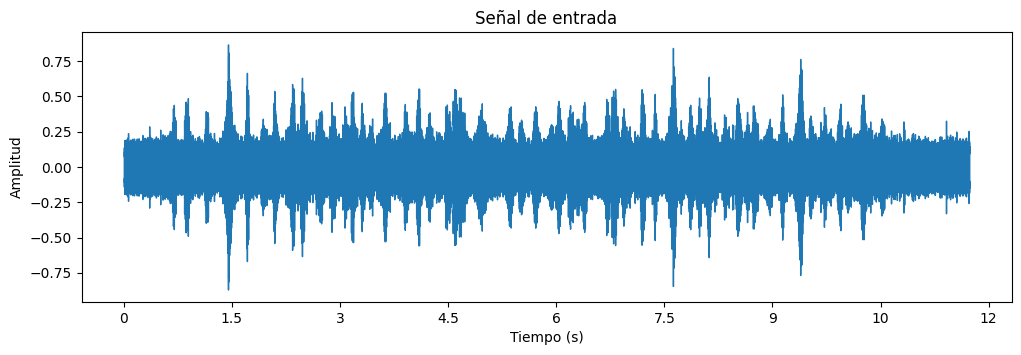

In [3]:
plt.figure(figsize=(12,3.5))
librosa.display.waveshow(entrada, sr=sr)
plt.title('Señal de entrada')
plt.xlabel('Tiempo (s)')
plt.ylabel('Amplitud')
plt.show()

## 4. Espectrograma mediante STFT
La STFT representa la señal en ventanas cortas. Se usa una FFT de 512 puntos y un salto de 128 muestras, suficiente para visualizar cómo cambia el contenido frecuencial a lo largo del tiempo.

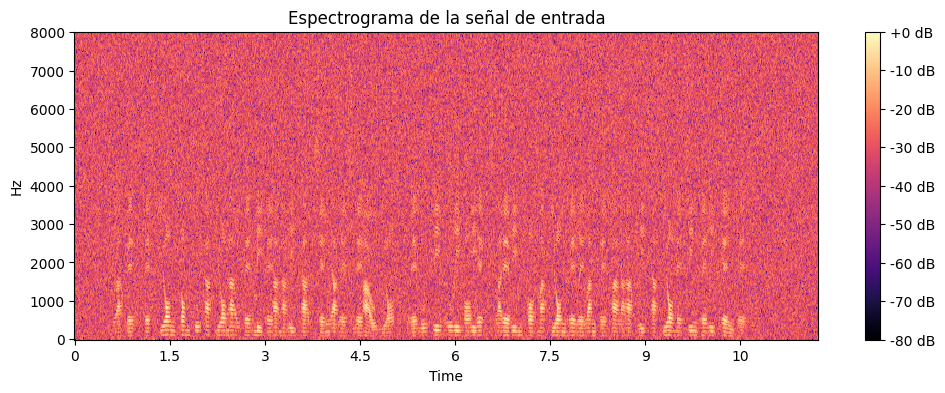

In [4]:
D = librosa.amplitude_to_db(
    np.abs(librosa.stft(entrada, n_fft=512, hop_length=128)), ref=np.max)
plt.figure(figsize=(12,4))
librosa.display.specshow(D, sr=sr, hop_length=128, x_axis='time', y_axis='hz')
plt.colorbar(format='%+2.0f dB')
plt.title('Espectrograma de la señal de entrada')
plt.show()

## 5. Tratamiento: reducción de ruido por sustracción espectral
Se estima el perfil de ruido a partir de los primeros 0,45 s. Para cada bin frecuencial se resta una fracción del perfil estimado. Se conserva un piso espectral para evitar discontinuidades y artefactos excesivos.

In [5]:
f, t, Z = stft(entrada, fs=sr, nperseg=512, noverlap=384, window='hann')
magnitud = np.abs(Z)
fase = np.angle(Z)

tramas_ruido = t < 0.45
perfil_ruido = np.mean(magnitud[:, tramas_ruido], axis=1, keepdims=True)
alpha = 1.25
piso = 0.04 * perfil_ruido
magnitud_limpia = np.maximum(magnitud - alpha * perfil_ruido, piso)

Z_limpia = magnitud_limpia * np.exp(1j * fase)
_, tratado = istft(Z_limpia, fs=sr, nperseg=512, noverlap=384, window='hann')
tratado = tratado[:len(entrada)]
tratado = tratado / (np.max(np.abs(tratado)) + 1e-12) * 0.90
sf.write('audio_tratado.wav', tratado, sr)

display(Audio(tratado, rate=sr))

## 6. Detección de actividad de voz (VAD) y recorte
Se calcula la energía RMS sobre tramas de 25 ms, desplazadas cada 10 ms. El umbral se obtiene a partir del nivel de las primeras tramas, correspondientes al ruido de fondo. Se suaviza la decisión para evitar activaciones aisladas.

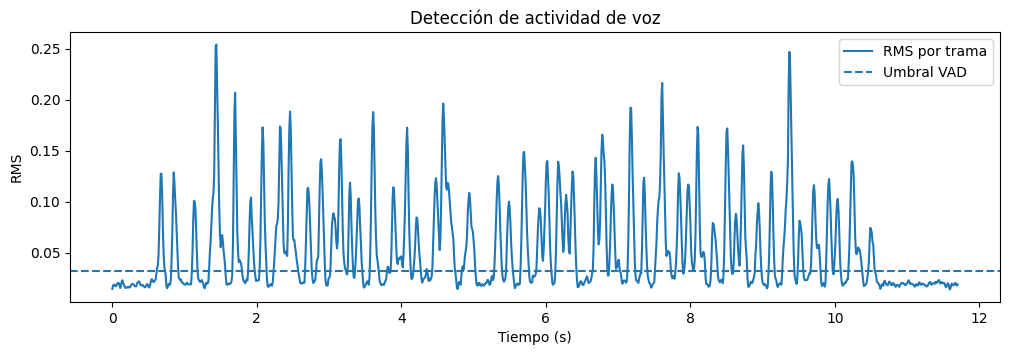

Recorte detectado: 0.49 s a 10.71 s
Duración útil: 10.22 s


In [6]:
frame = int(0.025 * sr)
hop = int(0.010 * sr)
tramas = librosa.util.frame(tratado, frame_length=frame, hop_length=hop)
rms = np.sqrt(np.mean(tramas**2, axis=0))
tiempos = np.arange(len(rms)) * hop / sr

n_inicial = max(1, int(0.45 / 0.01))
rms_ruido = np.median(rms[:n_inicial])
umbral = max(rms_ruido * 1.8, np.percentile(rms, 25) * 1.25)
actividad = rms > umbral
actividad_suave = np.convolve(actividad.astype(float), np.ones(8)/8, mode='same') > 0.35

indices = np.where(actividad_suave)[0]
if len(indices):
    inicio = max(0, int(indices[0]*hop - 0.12*sr))
    fin = min(len(tratado), int(indices[-1]*hop + frame + 0.12*sr))
else:
    inicio, fin = 0, len(tratado)

tratado_recortado = tratado[inicio:fin]
sf.write('audio_tratado_recortado.wav', tratado_recortado, sr)

plt.figure(figsize=(12,3.5))
plt.plot(tiempos, rms, label='RMS por trama')
plt.axhline(umbral, linestyle='--', label='Umbral VAD')
plt.xlabel('Tiempo (s)'); plt.ylabel('RMS')
plt.title('Detección de actividad de voz')
plt.legend(); plt.show()

print(f'Recorte detectado: {inicio/sr:.2f} s a {fin/sr:.2f} s')
print(f'Duración útil: {len(tratado_recortado)/sr:.2f} s')

## 7. Comparación visual después del tratamiento

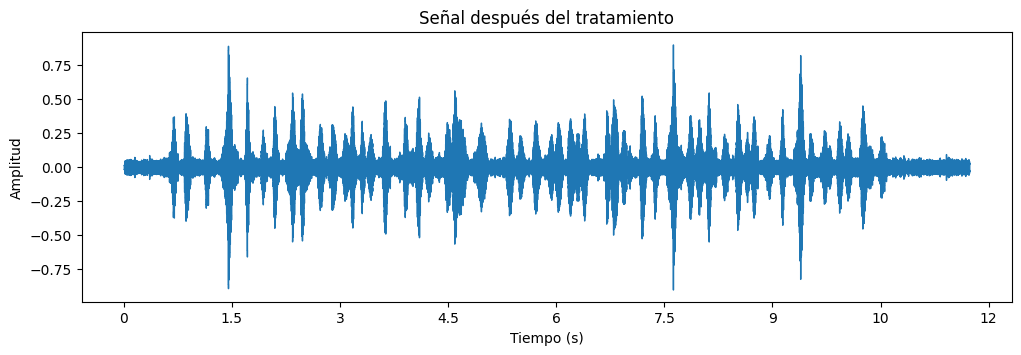

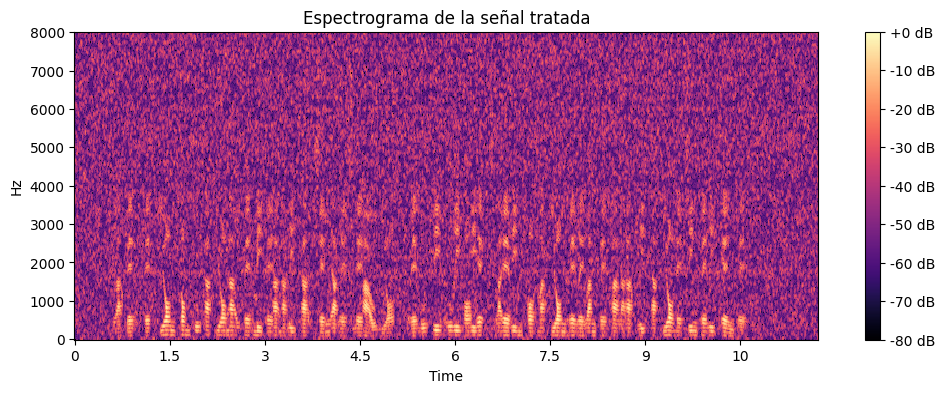

In [7]:
plt.figure(figsize=(12,3.5))
librosa.display.waveshow(tratado, sr=sr)
plt.title('Señal después del tratamiento')
plt.xlabel('Tiempo (s)'); plt.ylabel('Amplitud')
plt.show()

D2 = librosa.amplitude_to_db(
    np.abs(librosa.stft(tratado, n_fft=512, hop_length=128)), ref=np.max)
plt.figure(figsize=(12,4))
librosa.display.specshow(D2, sr=sr, hop_length=128, x_axis='time', y_axis='hz')
plt.colorbar(format='%+2.0f dB')
plt.title('Espectrograma de la señal tratada')
plt.show()

## 8. Métricas
Para el modo `demo` existe una referencia limpia, por lo cual se calcula SNR antes y después. Para un audio real cargado por el usuario, se reportan las métricas que no necesitan referencia limpia.

In [8]:
def rms_global(y):
    return float(np.sqrt(np.mean(y**2)))

def snr_db(ref, test):
    error = test - ref
    return float(10*np.log10((np.sum(ref**2)+1e-12)/(np.sum(error**2)+1e-12)))

metricas = {
    'frecuencia_muestreo_hz': sr,
    'duracion_entrada_s': len(entrada)/sr,
    'duracion_util_s': len(tratado_recortado)/sr,
    'rms_entrada': rms_global(entrada),
    'rms_salida': rms_global(tratado),
    'centroide_espectral_entrada_hz': float(np.mean(librosa.feature.spectral_centroid(y=entrada, sr=sr))),
    'centroide_espectral_salida_hz': float(np.mean(librosa.feature.spectral_centroid(y=tratado, sr=sr))),
    'pico_entrada': float(np.max(np.abs(entrada))),
    'pico_salida': float(np.max(np.abs(tratado))),
}

if referencia_limpia is not None:
    metricas['snr_antes_db'] = snr_db(referencia_limpia, entrada)
    metricas['snr_despues_db'] = snr_db(referencia_limpia, tratado)
    metricas['mejora_snr_db'] = metricas['snr_despues_db'] - metricas['snr_antes_db']

for k,v in metricas.items():
    print(f'{k}: {v:.4f}' if isinstance(v,float) else f'{k}: {v}')

with open('metricas_audio.json','w',encoding='utf-8') as f:
    json.dump(metricas,f,indent=2,ensure_ascii=False)

frecuencia_muestreo_hz: 16000
duracion_entrada_s: 11.7312
duracion_util_s: 10.2250
rms_entrada: 0.0938
rms_salida: 0.0703
centroide_espectral_entrada_hz: 3645.9904
centroide_espectral_salida_hz: 3073.0717
pico_entrada: 0.8679
pico_salida: 0.9000
snr_antes_db: 0.1738
snr_despues_db: 7.6118
mejora_snr_db: 7.4380


## 9. Interpretación de resultados
En el modo demostración con semilla fija, la reducción de ruido debe incrementar la SNR de manera visible y reducir el contenido espectral de banda ancha. El VAD delimita la región principal de voz y permite retirar segmentos iniciales/finales que no aportan información relevante.

La mejora no implica reconstrucción perfecta: la sustracción espectral puede introducir artefactos si el perfil de ruido cambia en el tiempo o si se utiliza un factor de resta demasiado alto. Por ello, el método funciona como una solución de preprocesamiento simple, interpretable y reproducible.

## 10. Archivos generados
Al finalizar se generan:
- `audio_entrada_ruidoso.wav` (modo demo)
- `audio_tratado.wav`
- `audio_tratado_recortado.wav`
- `metricas_audio.json`

Estos archivos pueden descargarse desde el panel de archivos de Google Colab e incorporarse al repositorio GitHub junto con este notebook.

In [9]:
print('Archivos disponibles:')
for nombre in ['audio_entrada_ruidoso.wav','audio_tratado.wav','audio_tratado_recortado.wav','metricas_audio.json']:
    if os.path.exists(nombre):
        print('-', nombre)

Archivos disponibles:
- audio_entrada_ruidoso.wav
- audio_tratado.wav
- audio_tratado_recortado.wav
- metricas_audio.json


## Referencias de apoyo
- Girish, K. V. V. (2019). *Beginner’s guide to Speech Analysis*. Medium / TDS Archive.
- freeCodeCamp.org. (2022). *Python Speech Recognition Tutorial – Full Course for Beginners* [Video]. YouTube.
- McFee, B., et al. (2015). librosa: Audio and music signal analysis in Python. *Proceedings of the 14th Python in Science Conference*, 18–25.